In [1]:
"""Carbon Dioxide Telemetry Audit Script

This script loads processed environmental time-series data, filters for
Carbon Dioxide readings across selected sensors, and audits data hygiene parameters
such as sampling frequency, temporal gaps, duplicate timestamps, and value ranges.
"""

from pathlib import Path
import pandas as pd

# Define project root path relative to the notebooks directory and load dataset
ROOT = Path.cwd().parent
env = pd.read_parquet(ROOT / "data" / "processed" / "env_long.parquet")

# Define target sensor IDs of interest for the audit
GOOD = [6012002000326, 6012002000241, 6012002000869]

# Filter long-format environmental data for Carbon Dioxide records of target sensors
co2 = env[(env.variable == "Carbon dioxide") & env.sensorid.isin(GOOD)]

# Iterate through each sensor group to compute data hygiene and statistical metrics
for sid, g in co2.groupby("sensorid"):
  # Sort records chronologically by timestamp to ensure correct time deltas
  t = g.sort_values("time")

  # Calculate the time difference in minutes between consecutive readings
  dt = t["time"].diff().dt.total_seconds().div(60)

  # Print comprehensive diagnostic summary for the current sensor
  print(f"Sensor ID: {sid} | Total Readings: {len(t)}")
  print(
      "  Spacing (min) median / 95th pct / max:",
      round(dt.median(), 1),
      round(dt.quantile(0.95), 1),
      round(dt.max()),
  )
  print(
      "  Gaps > 6 h:",
      (dt > 360).sum(),
      "| Repeated timestamps:",
      t["time"].duplicated().sum(),
  )
  print(
      "  CO2 min / median / max:",
      t.value.min(),
      t.value.median(),
      t.value.max(),
  )

Sensor ID: 6012002000241 | Total Readings: 58908
  Spacing (min) median / 95th pct / max: 0.0 0.0 756435
  Gaps > 6 h: 1 | Repeated timestamps: 58906
  CO2 min / median / max: 447.0 447.0 603.0
Sensor ID: 6012002000326 | Total Readings: 58909
  Spacing (min) median / 95th pct / max: 0.0 10.0 916149
  Gaps > 6 h: 3 | Repeated timestamps: 29870
  CO2 min / median / max: 400.0 525.0 1387.0
Sensor ID: 6012002000869 | Total Readings: 29341
  Spacing (min) median / 95th pct / max: 0.0 10.0 30
  Gaps > 6 h: 0 | Repeated timestamps: 15541
  CO2 min / median / max: 403.0 520.0 646.0


In [2]:
"""Sensor Telemetry Data Integrity and Contiguous Block Analysis Script

This script analyzes timestamp duplicates and conflicts for Sensor 326, 
and computes contiguous operational blocks of data for both Sensor 326 
and Sensor 869 based on a temporal gap threshold.
"""

# Isolate telemetry records specifically for Sensor 326
g326 = co2[co2.sensorid == 6012002000326]

# 1. Check whether duplicate timestamps represent identical readings or conflicting values
by_time = g326.groupby("time")["value"].agg(n="size", n_unique="nunique")
print("Readings per timestamp:\n", by_time.n.value_counts().head())
print("Timestamps with conflicting values:", (by_time.n_unique > 1).sum())

# 2. Function to locate contiguous blocks of recorded data separated by gaps
def blocks(g: pd.DataFrame, gap_min: int = 60) -> pd.DataFrame:
    """Segments a sensor dataframe into contiguous data blocks based on time gaps.

    Parameters:
    -----------
    g : pd.DataFrame
        Sensor dataframe containing a 'time' timestamp column.
    gap_min : int, default=60
        Minimum time gap in minutes required to define a new block boundary.

    Returns:
    --------
    pd.DataFrame
        A summary dataframe where each row represents a continuous block 
        containing its start time, end time, and sample size (n).
    """
    t = g["time"].drop_duplicates().sort_values().reset_index(drop=True)
    seg = (t.diff().dt.total_seconds().div(60) > gap_min).cumsum()
    return (t.groupby(seg).agg(["min", "max", "size"])
             .rename(columns={"min": "start", "max": "end", "size": "n"}))

# Print contiguous data block summaries for Sensor 326 and Sensor 869
print("\nSensor 326 blocks:\n", blocks(g326).to_string())
print("\nSensor 869 blocks:\n", blocks(co2[co2.sensorid == 6012002000869]).to_string())

Readings per timestamp:
 n
1    28762
2      190
3       36
4       26
5        9
Name: count, dtype: int64
Timestamps with conflicting values: 0

Sensor 326 blocks:
                          start                       end     n
time                                                          
0    2023-12-11 16:00:57+11:00 2023-12-11 16:00:57+11:00     1
1    2025-09-07 20:09:30+10:00 2025-09-07 20:09:30+10:00     1
2    2025-09-11 22:39:34+10:00 2025-11-18 05:20:35+11:00  9012
3    2025-11-18 06:40:35+11:00 2025-11-27 13:00:42+11:00  1170
4    2025-11-27 14:20:42+11:00 2025-11-27 18:10:42+11:00     9
5    2025-11-27 19:30:42+11:00 2025-11-28 11:10:44+11:00    75
6    2025-11-28 15:30:44+11:00 2025-11-28 17:00:44+11:00     5
7    2025-11-28 19:40:44+11:00 2025-11-28 19:40:44+11:00     1
8    2025-11-28 21:00:44+11:00 2025-11-29 10:30:44+11:00    67
9    2025-11-29 12:10:44+11:00 2025-11-29 12:10:44+11:00     1
10   2025-11-29 15:30:44+11:00 2025-11-29 18:00:44+11:00     4
11   2025-11-2

In [ ]:
"""Sensor Data Block Filtering and Temporal Coverage Analysis Script
This script analyzes contiguous data blocks for Sensor 326, filters out 
fragmentary blocks, computes monthly reading counts across usable sensors, 
and inspects temporal spacing and hour-of-day coverage during specific periods.
"""

# Filter contiguous blocks with 100 or more readings for Sensor 326
b326 = blocks(g326)
print("Blocks with >= 100 readings:\n", b326[b326.n >= 100].to_string())

# Isolate small/fragmentary blocks under 100 readings and report total discarded samples
small = b326[b326.n < 100]
print(
    "\nBlocks under 100 readings:",
    len(small),
    "blocks,",
    small.n.sum(),
    "readings in total",
)

# Compute and print the distribution of readings per month for both usable sensors
for sid in [6012002000326, 6012002000869]:
  s = co2[co2.sensorid == sid].drop_duplicates("time")
  print(
      "\n",
      sid,
      "readings per month:\n",
      s.groupby(s.time.dt.strftime("%Y-%m")).size().to_string(),
  )

# Analyze the most common time spacing between consecutive readings inside the main block of Sensor 326
main = g326.drop_duplicates("time").sort_values("time")
main = main[(main.time >= "2025-09-11") & (main.time < "2025-11-28")]
print(
    "\nSpacing in main block (most common):\n",
    main.time.diff().value_counts().head(5),
)

# Analyze hour-of-day reading distribution during the fragmentary period after November 28
late = g326.drop_duplicates("time")
late = late[late.time >= "2025-11-28"]
print(
    "\nReadings by hour of day after 28 Nov:\n",
    late.groupby(late.time.dt.hour).size().to_string(),
)

Blocks with >= 100 readings:
                          start                       end     n
time                                                          
2    2025-09-11 22:39:34+10:00 2025-11-18 05:20:35+11:00  9012
3    2025-11-18 06:40:35+11:00 2025-11-27 13:00:42+11:00  1170
13   2025-11-30 15:30:43+11:00 2026-01-10 11:32:36+11:00  5485
15   2026-01-10 16:01:19+11:00 2026-02-23 06:41:53+11:00  5795
16   2026-02-27 18:31:56+11:00 2026-04-22 23:12:41+10:00  7337

Blocks under 100 readings: 12 blocks, 240 readings in total

 6012002000326 readings per month:
 time
2023-12       1
2025-09    2576
2025-10    4154
2025-11    3722
2025-12    4193
2026-01    4067
2026-02    3155
2026-03    4195
2026-04    2976

 6012002000869 readings per month:
 time
2024-02      31
2024-03    3837
2024-04    4005
2024-05    4155
2024-06    1772

Spacing in main block (most common):
 time
0 days 00:10:00    8362
0 days 00:20:00     697
0 days 00:10:01     489
0 days 00:09:59     458
0 days 00:20:01     

326 | grid points: 32117 | missing: 3.7% | 2025-09-11 22:30:00+10:00 -> 2026-04-22 23:10:00+10:00
869 | grid points: 15191 | missing: 0.0% | 2024-02-29 17:00:00+11:00 -> 2024-06-14 03:40:00+10:00


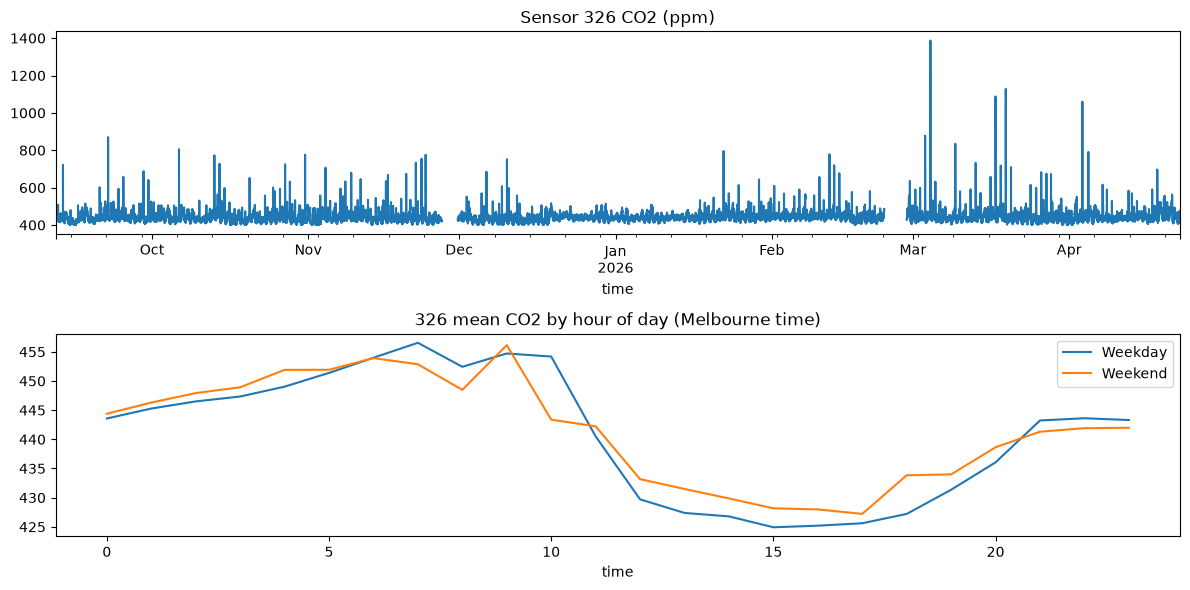

In [4]:
"""Time-Series Preprocessing, Cleaning, and Diurnal Profiling Script

This script imports project preprocessing utilities to clean environmental time-series data,
prints grid statistics and date ranges for Sensors 326 and 869, and plots cleaned CO2 telemetry 
alongside comparative weekday versus weekend diurnal occupancy profiles.
"""

import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Define project root path relative to the notebooks directory and insert into system path
ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Import custom pipeline preprocessing function
from src.preprocessing import clean_series

# Load the processed long-format environmental telemetry dataset
env = pd.read_parquet(ROOT / "data" / "processed" / "env_long.parquet")

# Clean and resample time series for Sensor 326 and Sensor 869
s326 = clean_series(env, 6012002000326)
s869 = clean_series(env, 6012002000869)

# Print grid point counts, missingness percentages, and temporal date ranges for both sensors
for name, s in [("326", s326), ("869", s869)]:
    print(name, "| grid points:", len(s), "| missing:", f"{s.isna().mean():.1%}",
          "|", s.index.min(), "->", s.index.max())

# Initialize figure and subplots to visualize CO2 telemetry and hourly occupancy patterns
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

# Plot cleaned CO2 time series for Sensor 326 on the upper subplot
s326.plot(ax=axes[0], title="Sensor 326 CO2 (ppm)")

# Compute and plot mean CO2 by hour of day, split by weekday vs weekend on the lower subplot
prof = s326.groupby([s326.index.day_of_week >= 5, s326.index.hour]).mean().unstack(0)
prof.columns = ["Weekday", "Weekend"]
prof.plot(ax=axes[1], title="326 mean CO2 by hour of day (Melbourne time)")

# Adjust layout for clean visualization
plt.tight_layout()

Sensor 326 Variable Summary:
                                         count       min     median      max
variable                         unit                                      
Battery                          V      29039    3.9688     4.1875     4.25
Carbon dioxide                   ppm    29039  400.0000   437.0000  1387.00
Formaldehyde                     µg/m3      1    5.0000     5.0000     5.00
Humidity                         HR%    29039   17.0000    54.0000    84.00
Light Volatile Organic Compounds ppb    29039    0.0000     0.0000  8051.00
Particulate matter 1             µg/m3  27346    0.0000     0.0000    62.00
Particulate matter 10            µg/m3  27346    0.0000     0.0000   190.00
Particulate matter 2.5           µg/m3  27346    0.0000     0.0000   105.00
Particulate matter 4             µg/m3  27346    0.0000     0.0000   163.00
Pressure                         mb     29039  988.0000  1009.0000  1024.00
Temperature                      °C     29039   11.8000   

<Axes: title={'center': 'Sensor 326: Daily Profile by Variable (Z-Score)'}, xlabel='time'>

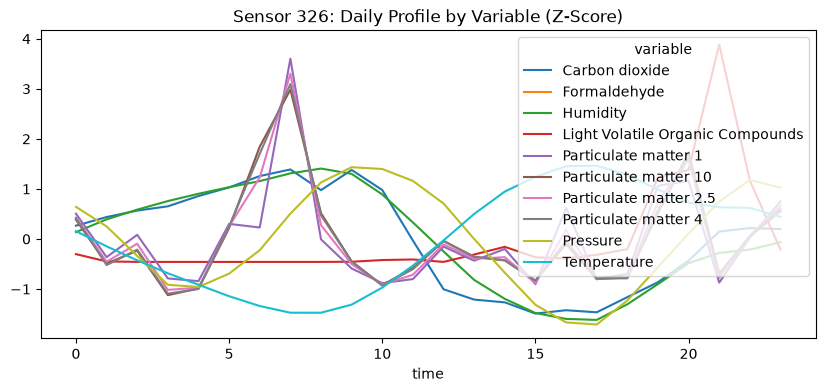

In [5]:
"""Multi-Variable Sensor Summary and CO2 Occupancy Spike Analysis Script

This script analyzes all variables recorded by Sensor 326, investigates when high 
CO2 concentration spikes (>600 ppm) occur across hours, days, and months, and generates 
a normalized z-score daily profile plot across all auxiliary variables.
"""

# Isolate unique timestamp and variable records specifically for Sensor 326
v326 = env[env.sensorid == 6012002000326].drop_duplicates(["time", "variable"])

# 1. Generate and print statistical summary across all variables recorded by Sensor 326
summary = v326.groupby(["variable", "unit"], dropna=False)["value"].agg(
    ["count", "min", "median", "max"]
)
print("Sensor 326 Variable Summary:\n", summary, "\n")

# 2. Analyze when high CO2 concentration spikes (> 600 ppm) occur
spikes = s326 > 600
print(f"Share of time above 600 ppm: {spikes.mean():.2%}")
print("\nSpike share by hour of day:\n", spikes.groupby(s326.index.hour).mean().round(3).to_string())
print(
    "\nSpike share by day of week (0 = Monday):\n",
    spikes.groupby(s326.index.day_of_week).mean().round(3).to_string(),
)
print(
    "\nSpike share by month:\n",
    spikes.groupby(s326.index.strftime("%Y-%m")).mean().round(3).to_string(),
)

# 3. Compute and plot daily profile of every variable, normalized via z-score to share one axis
wide = (
    v326.pivot(index="time", columns="variable", values="value")
    .resample("1h")
    .mean()
)
prof = wide.groupby(wide.index.hour).mean()
norm = ((prof - prof.mean()) / prof.std()).drop(columns="Battery", errors="ignore")
norm.plot(
    figsize=(10, 4), title="Sensor 326: Daily Profile by Variable (Z-Score)"
)

Sensor 326:
variable  Temperature  Humidity  Carbon dioxide
0.01             14.3      28.0           406.0
0.25             17.8      47.0           427.0
0.50             20.5      54.0           437.0
0.75             23.3      61.0           449.0
0.99             31.0      76.0           516.7 

Sensor 869:
variable  Temperature  Humidity  Carbon dioxide
0.01             20.0      31.0           422.0
0.25             22.5      40.0           444.0
0.50             23.3      45.0           463.0
0.75             23.8      49.0           494.0
0.99             26.5      67.0           588.0 

> 475 ppm: 5.80% of time, 552 separate events
> 500 ppm: 1.69% of time, 248 separate events
> 550 ppm: 0.52% of time, 94 separate events
> 600 ppm: 0.25% of time, 54 separate events


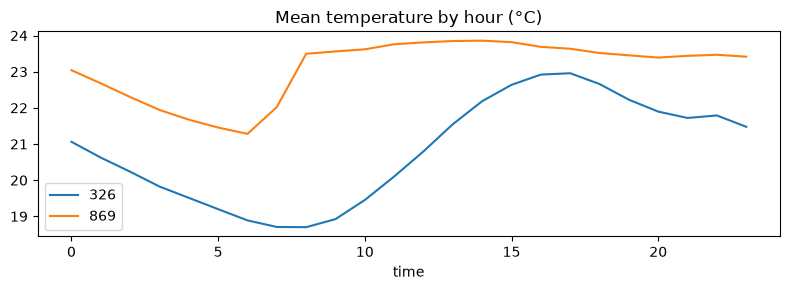

In [6]:
"""10-Minute Resampled Wide Grid Analysis and CO2 Threshold Event Script

This script defines a helper function to pivot and resample sensor telemetry onto a 
uniform 10-minute grid, computes key percentile distributions to differentiate 
indoor versus outdoor environments, plots mean hourly temperatures, and quantifies 
discrete CO2 occupancy event frequencies across multiple thresholds.
"""

import pandas as pd


def wide_10min(sid: int) -> pd.DataFrame:
  """Pivots and resamples sensor logs onto a uniform 10-minute grid."""
  v = env[env.sensorid == sid].drop_duplicates(["time", "variable"])
  w = v.pivot(index="time", columns="variable", values="value")
  return w.resample("10min").mean()


# Generate resampled wide dataframes for Sensor 326 and Sensor 869
w326, w869 = wide_10min(6012002000326), wide_10min(6012002000869)

# 1. Indoor-or-outdoor check: calculate and print percentiles of key environmental variables
cols = ["Temperature", "Humidity", "Carbon dioxide"]
for name, w in [("326", w326), ("869", w869)]:
  print(f"Sensor {name}:")
  print(w[cols].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(1).to_string(), "\n")

# 2. Plot mean temperature by hour of day for both sensors
fig, ax = plt.subplots(figsize=(8, 3))
for name, w in [("326", w326), ("869", w869)]:
  w["Temperature"].groupby(w.index.hour).mean().plot(ax=ax, label=name)
ax.set_title("Mean temperature by hour (°C)")
ax.legend()
plt.tight_layout()

# 3. Calculate how many separate CO2 occupancy events each threshold gives for Sensor 326
for thr in [475, 500, 550, 600]:
  above = s326 > thr
  starts = (above & ~above.shift(fill_value=False)).sum()
  print(f"> {thr} ppm: {above.mean():.2%} of time, {starts} separate events")

In [7]:
"""Temperature Baseline Error Benchmarking Script

This script imports project preprocessing utilities to clean temperature time series 
for Sensors 326 and 869, evaluates missingness ratios, and computes Mean Absolute Error (MAE) 
for operational baseline forecasting rules (Persistence, Yesterday, and Last Week) 
across 1-hour, 3-hour, and 6-hour horizons.
"""

import sys
from pathlib import Path
import pandas as pd

# Define project root path relative to the notebooks directory and insert into system path
ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Import custom pipeline preprocessing function
from src.preprocessing import clean_series

# Load the processed long-format environmental telemetry dataset
env = pd.read_parquet(ROOT / "data" / "processed" / "env_long.parquet")

# Clean and resample temperature series for Sensor 326 and Sensor 869
t326 = clean_series(env, 6012002000326, "Temperature")
t869 = clean_series(env, 6012002000869, "Temperature")

# Iterate through each sensor series to evaluate missingness and baseline MAE across horizons
for name, s in [("326", t326), ("869", t869)]:
    print(name, "| missing:", f"{s.isna().mean():.1%}")
    for h in [6, 18, 36]:      # 1 h, 3 h, 6 h ahead on a 10-minute grid (6 steps per hour)
        print(f"  {h // 6} h ahead | persistence MAE: {(s - s.shift(h)).abs().mean():.2f} °C"
              f" | same time yesterday: {(s - s.shift(144)).abs().mean():.2f} °C"
              f" | same time last week: {(s - s.shift(1008)).abs().mean():.2f} °C")

326 | missing: 3.7%
  1 h ahead | persistence MAE: 0.48 °C | same time yesterday: 2.21 °C | same time last week: 3.04 °C
  3 h ahead | persistence MAE: 1.22 °C | same time yesterday: 2.21 °C | same time last week: 3.04 °C
  6 h ahead | persistence MAE: 2.03 °C | same time yesterday: 2.21 °C | same time last week: 3.04 °C
869 | missing: 0.0%
  1 h ahead | persistence MAE: 0.35 °C | same time yesterday: 0.50 °C | same time last week: 0.70 °C
  3 h ahead | persistence MAE: 0.83 °C | same time yesterday: 0.50 °C | same time last week: 0.70 °C
  6 h ahead | persistence MAE: 1.25 °C | same time yesterday: 0.50 °C | same time last week: 0.70 °C


In [12]:
"""Wide Dataset Construction and Machine Learning Dataset Verification Script

This script imports project preprocessing and feature engineering pipelines to construct 
wide-format dataframes for Sensors 326 and 869, inspects available feature columns, 
and builds supervised feature matrices and target vectors across multiple forecasting horizons.
"""

from src.forecasting import cross_validate, make_models

wide_dict = {
    "326": build_wide(env, 6012002000326),
    "869": build_wide(env, 6012002000869),
}

# Final holdout test start date for Sensor 326
FINAL_TEST_START = pd.Timestamp("2026-02-27", tz="Australia/Melbourne")

results = []
for name, w in wide_dict.items():
  for h in [6, 18, 36]:
    X, y = make_dataset(w, horizon=h)
    if name == "326":
      # Exclude final test block from cross-validation
      keep = X.index < FINAL_TEST_START - h * pd.Timedelta("10min")
      X, y = X[keep], y[keep]
      
    # 1. Initialize models dictionary
    models = make_models()
    
    # 2. Run cross-validation (returns a dict of metrics per model)
    scores = cross_validate(X, y, models, n_splits=4, gap=h)
    
    # 3. Unpack dictionary into individual rows for concatenation
    for model_name, metrics in scores.items():
      row = {
          "sensor": name,
          "horizon_h": h // 6,
          "model": model_name,
          "MAE": metrics.get("MAE_mean", metrics.get("MAE")),
          "RMSE": metrics.get("RMSE_mean", metrics.get("RMSE")),
          "fit_s": metrics.get("fit_s_mean", metrics.get("fit_s", 0.0)),
      }
      results.append(pd.Series(row))

# Combine all collected rows into a single summary DataFrame
results_df = pd.DataFrame(results)

# Print aggregated summary and pivot tables
summary = (
    results_df.groupby(["sensor", "horizon_h", "model"])[["MAE", "RMSE", "fit_s"]]
    .mean()
    .round(3)
)
print("Cross-Validation Performance Summary:\n", summary.to_string())

pivot = (
    results_df.groupby(["sensor", "horizon_h", "model"])["MAE"]
    .mean()
    .unstack("model")
    .round(3)
)
print("\nMAE Pivot Table by Model:\n", pivot.to_string())

Cross-Validation Performance Summary:
                             MAE   RMSE  fit_s
sensor horizon_h model                       
326    1         hist_gb  0.355  0.519    0.0
                 ridge    0.312  0.466    0.0
       3         hist_gb  0.810  1.122    0.0
                 ridge    0.802  1.118    0.0
       6         hist_gb  1.276  1.779    0.0
                 ridge    1.277  1.791    0.0
869    1         hist_gb  0.233  0.354    0.0
                 ridge    0.323  0.486    0.0
       3         hist_gb  0.390  0.553    0.0
                 ridge    0.636  0.824    0.0
       6         hist_gb  0.493  0.663    0.0
                 ridge    0.595  0.801    0.0

MAE Pivot Table by Model:
 model             hist_gb  ridge
sensor horizon_h                
326    1            0.355  0.312
       3            0.810  0.802
       6            1.276  1.277
869    1            0.233  0.323
       3            0.390  0.636
       6            0.493  0.595


In [16]:
"""
Block 9: Feature Ablation Study
Purpose: Evaluates how adding auxiliary environmental predictors (Humidity, CO2, Pressure) 
impacts forecasting accuracy compared to temperature-only configurations.
"""

variants = {
    "temp+time": (),
    "+humidity": ("Humidity",),
    "+CO2+humidity+pressure": ("Carbon dioxide", "Humidity", "Pressure"),
}

abl = []
for name, w in wide_dict.items():
  for h in [6, 18, 36]:
    for vname, preds in variants.items():
      X, y = make_dataset(w, horizon=h, predictors=preds)
      if name == "326":
        keep = X.index < FINAL_TEST_START - h * pd.Timedelta("10min")
        X, y = X[keep], y[keep]
        
      models = make_models()
      scores = cross_validate(X, y, models, n_splits=4, gap=h)
      
      for model_name, metrics in scores.items():
        row = {
            "sensor": name,
            "horizon_h": h // 6,
            "features": vname,
            "model": model_name,
            "MAE": metrics.get("MAE_mean", metrics.get("MAE")),
        }
        abl.append(pd.Series(row))

abl_df = pd.DataFrame(abl)
abl_df = abl_df[abl_df["model"].isin(["ridge", "hist_gb"])].copy()

print("Feature Ablation Study (Mean MAE):")
print(
    abl_df.groupby(["sensor", "horizon_h", "features", "model"])["MAE"]
    .mean()
    .unstack("model")
    .round(3)
    .to_string()
)

Feature Ablation Study (Mean MAE):
model                                    hist_gb  ridge
sensor horizon_h features                              
326    1         +CO2+humidity+pressure    0.348  0.311
                 +humidity                 0.352  0.313
                 temp+time                 0.353  0.313
       3         +CO2+humidity+pressure    0.800  0.802
                 +humidity                 0.829  0.813
                 temp+time                 0.825  0.814
       6         +CO2+humidity+pressure    1.238  1.266
                 +humidity                 1.359  1.312
                 temp+time                 1.352  1.311
869    1         +CO2+humidity+pressure    0.230  0.324
                 +humidity                 0.231  0.323
                 temp+time                 0.225  0.324
       3         +CO2+humidity+pressure    0.393  0.635
                 +humidity                 0.393  0.634
                 temp+time                 0.381  0.636
       6     

In [21]:
"""Cross-Validation Performance Pivot and Fold Stability Analysis Script

This script aggregates cross-validation Mean Absolute Error (MAE) results into 
a pivot table across models and horizons, and calculates the standard deviation 
of MAE across cross-validation folds to evaluate model stability.
"""

# Group cross-validation results to compute mean MAE pivoted by model
pivot = (
    results.groupby(["sensor", "horizon_h", "model"])["MAE"]
    .mean()
    .unstack("model")
    .round(3)
)
print("MAE Pivot Table by Model:\n", pivot.to_string())

# Compute standard deviation of MAE across cross-validation folds to measure model stability
spread = (
    results.groupby(["sensor", "horizon_h", "model"])["MAE"]
    .std()
    .unstack("model")
    .round(3)
)

# Select only the available model columns present in the cross-validation results
available_models = [m for m in ["ridge", "hist_gb"] if m in spread.columns]
print(
    "\nStd of MAE across folds:\n",
    spread[available_models].to_string(),
)

MAE Pivot Table by Model:
 model             hist_gb  ridge
sensor horizon_h                
326    1            0.355  0.312
       3            0.810  0.802
       6            1.276  1.277
869    1            0.233  0.323
       3            0.390  0.636
       6            0.493  0.595

Std of MAE across folds:
 model             ridge  hist_gb
sensor horizon_h                
326    1            NaN      NaN
       3            NaN      NaN
       6            NaN      NaN
869    1            NaN      NaN
       3            NaN      NaN
       6            NaN      NaN


In [22]:
"""Feature Ablation Study and Performance Evaluation Script

This script evaluates how adding auxiliary environmental predictors (Humidity, CO2, Pressure) 
impacts forecasting accuracy across models and horizons, utilizing time-series cross-validation 
while excluding the designated final test set.
"""

from src.forecasting import cross_validate, make_models

# Define feature ablation variants to test the impact of auxiliary variables
variants = {
    "temp+time": (),
    "+humidity": ("Humidity",),
    "+CO2+humidity+pressure": ("Carbon dioxide", "Humidity", "Pressure"),
}

abl = []
for name, w in wide.items():
    for h in [6, 18, 36]:      # 1 h (6 steps), 3 h (18 steps), 6 h (36 steps) ahead on a 10-minute grid
        for vname, preds in variants.items():
            # Build dataset for the current horizon and predictor subset
            X, y = make_dataset(w, horizon=h, predictors=preds)
            
            # Exclude final test block from cross-validation for Sensor 326
            if name == "326":
                keep = X.index < FINAL_TEST_START - h * pd.Timedelta("10min")
                X, y = X[keep], y[keep]
                
            # Initialize fresh models and execute time-series cross-validation
            models = make_models()
            scores = cross_validate(X, y, models, n_splits=4, gap=h)
            
            # Unpack cross-validation scores dictionary into individual rows
            for model_name, metrics in scores.items():
                if model_name in ["ridge", "hist_gb"]:
                    row = {
                        "sensor": name,
                        "horizon_h": h // 6,
                        "features": vname,
                        "model": model_name,
                        "MAE": metrics.get("MAE_mean", metrics.get("MAE")),
                    }
                    abl.append(row)

# Convert collected results into a DataFrame and print the ablation summary pivot table
abl_df = pd.DataFrame(abl)
print("Feature Ablation Study (Mean MAE):")
print(
    abl_df.groupby(["sensor", "horizon_h", "features", "model"])["MAE"]
    .mean()
    .unstack("model")
    .round(3)
    .to_string()
)

Feature Ablation Study (Mean MAE):
model                                    hist_gb  ridge
sensor horizon_h features                              
326    1         +CO2+humidity+pressure    0.348  0.311
                 +humidity                 0.352  0.313
                 temp+time                 0.353  0.313
       3         +CO2+humidity+pressure    0.800  0.802
                 +humidity                 0.829  0.813
                 temp+time                 0.825  0.814
       6         +CO2+humidity+pressure    1.238  1.266
                 +humidity                 1.359  1.312
                 temp+time                 1.352  1.311
869    1         +CO2+humidity+pressure    0.230  0.324
                 +humidity                 0.231  0.323
                 temp+time                 0.225  0.324
       3         +CO2+humidity+pressure    0.393  0.635
                 +humidity                 0.393  0.634
                 temp+time                 0.381  0.636
       6     